# Multiresolution Blending with a Laplacian Pyramid

In this notebook we merge an apple (on the left) with an orange (on the right)
so that the join looks natural — no visible straight line in the middle.

The idea is simple:

- A hard cut looks bad because it is a **step edge**. A step edge contains
  energy at *every* frequency, so the eye sees a sharp line no matter what
  you do with a single blur.
- The right fix is to split each image into **frequency bands** (coarse
  structure on one side, fine detail on the other) and blend each band over
  its **own width**: wide for coarse structure, narrow for fine detail.
- A **Laplacian pyramid** gives us those bands for free. It also gives us a
  **Gaussian pyramid of the mask** whose levels are already soft at the
  right width for each band.

The plan:

1. Load and align the two images.
2. Build a **sharp** binary mask (left half = 1, right half = 0).
3. Show what a hard cut looks like (as a baseline).
4. Build a Laplacian pyramid of each image and a Gaussian pyramid of the mask.
5. Combine level by level: `M·L1 + (1−M)·L2`.
6. Rebuild the image from the combined pyramid (collapse).
7. Show the seam for several pyramid depths and pick one.
8. For the chosen depth, show each level's contribution: `M·L1`,
   `(1−M)·L2` and their sum.

## 1. Setup

We only need NumPy, Matplotlib and the starter-pack helpers for loading and
aligning images. The path logic below finds the project root automatically.

In [18]:
%matplotlib inline
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
while not (ROOT / 'starter_pack').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'starter_pack').exists():
    raise FileNotFoundError('Could not locate the starter_pack directory')

sys.path.insert(0, str(ROOT))
IMAGE_DIR = ROOT / 'starter_pack' / 'images' / 'part2_frequencies'

from starter_pack.code.align_images import align_images
from starter_pack.code.utils import load_image

## 2. The theory in one page

### Why a hard cut shows a seam
A hard cut between two images is a **step edge**. A step contains energy at
every frequency. No matter what you do with a single Gaussian blur, you can
only soften **one** scale of that step. The other scales still jump at the
seam.

### Why band-by-band blending hides the seam
The eye is very sensitive to **large, low-frequency jumps** (a sudden
brightness / colour change) but much less sensitive to **small,
high-frequency jumps** (fine texture). So:

- **Fine levels (high frequency).** Blend the texture of the two fruits
  over a couple of pixels. The eye cannot see such a narrow transition
  because fine texture has low amplitude.
- **Coarse levels (low frequency).** Blend the overall colour and brightness
  over a wide region (tens or hundreds of pixels). A wide transition carries
  almost no low-frequency energy, so it looks like a gentle gradient, not a
  line.
- **Each band is blended over a width matched to its own scale.** That is
  what removes the seam without blurring the whole picture.

### How a Laplacian pyramid does this
- `G0, G1, G2, …` is the **Gaussian pyramid**: each level is the previous
  level, low-pass filtered and downsampled by 2. `G0` is the original image.
- The **Laplacian pyramid** is `L_i = G_i − expand(G_{i+1})`. It is the
  detail that was lost when we downsampled. The **coarsest level** is kept
  as-is (the low-frequency residual, not a difference).
- To blend, we take the **mask's Gaussian pyramid** `M_i`, and combine:
  `L_i_blended = M_i · L1_i + (1 − M_i) · L2_i`.
- `M_i` is already smooth at the right width for level `i` — no need to
  blur the mask manually.
- To rebuild, we "collapse" the pyramid: start at the coarsest level and
  `expand + add` our way back to full size.

## 3. Basic image filters

These are the same helpers we used before. `convolve_1d_reflect` reflects
the image at the borders so we never pad with zeros. We keep them because
the pyramid uses them, and so do the diagnostic plots.

In [19]:
def gaussian_kernel(sigma, radius=None):
    if sigma <= 0:
        raise ValueError('sigma must be positive')
    if radius is None:
        radius = int(np.ceil(3 * sigma))
    coordinates = np.arange(-radius, radius + 1, dtype=np.float32)
    kernel = np.exp(-(coordinates ** 2) / (2 * sigma ** 2))
    return kernel / kernel.sum()


def convolve_1d_reflect(image, kernel, axis):
    """1-D convolution with reflect padding, along `axis` (0 = rows, 1 = cols)."""
    radius = len(kernel) // 2
    if axis == 0:
        padded = np.pad(image, ((radius, radius), (0, 0)), mode='reflect')
        result = np.empty_like(image, dtype=np.float32)
        for row in range(image.shape[0]):
            result[row] = np.sum(padded[row:row + len(kernel)] * kernel[:, None], axis=0)
    elif axis == 1:
        padded = np.pad(image, ((0, 0), (radius, radius)), mode='reflect')
        result = np.empty_like(image, dtype=np.float32)
        for column in range(image.shape[1]):
            result[:, column] = np.sum(padded[:, column:column + len(kernel)] * kernel[None, :], axis=1)
    else:
        raise ValueError('axis must be 0 (rows) or 1 (columns)')
    return result


def convolve_reflect(image, kernel):
    if image.ndim != 2:
        raise ValueError(f'Expected a 2-D image, got shape {image.shape}')
    horizontal = convolve_1d_reflect(image, kernel, axis=1)
    return convolve_1d_reflect(horizontal, kernel, axis=0)


def gaussian_blur(image, sigma):
    if image.ndim not in (2, 3):
        raise ValueError(f'Expected a 2-D or 3-D image, got shape {image.shape}')
    kernel = gaussian_kernel(sigma)
    if image.ndim == 2:
        return convolve_reflect(image, kernel)
    channels = [convolve_reflect(image[:, :, c], kernel) for c in range(image.shape[2])]
    return np.stack(channels, axis=2)

## 4. Pyramid building blocks

We use the same **5-tap binomial kernel** `[1, 4, 6, 4, 1] / 16` for both
*reduce* (downsample) and *expand* (upsample). This is the classic
Burt & Adelson choice: it is nearly Gaussian and it is cheap.

- **`downsample`** = low-pass with the binomial kernel, then keep every
  second pixel.
- **`upsample`** = zero-insert, then low-pass with `2 × binomial` (gain
  factor 4 in total, so the average stays the same).
- **`gaussian_pyramid(img, L)`** returns `L + 1` levels: the original plus
  `L` progressively smaller versions.
- **`laplacian_pyramid`** returns `L + 1` levels: `L` band-pass levels
  plus the coarse residual (a plain Gaussian).
- **`collapse_laplacian`** rebuilds the image: start at the coarsest level
  and `expand + add` down to full size.

Everything is done channel by channel for colour images and directly for
the (single-channel) mask.

In [20]:
BINOMIAL = np.array([1, 4, 6, 4, 1], dtype=np.float32) / 16.0


def downsample(image):
    if image.ndim == 3:
        return np.stack([downsample(image[..., c]) for c in range(image.shape[2])], axis=-1)
    smooth = convolve_1d_reflect(image, BINOMIAL, axis=1)
    smooth = convolve_1d_reflect(smooth, BINOMIAL, axis=0)
    return smooth[::2, ::2]


def upsample(image, target_shape):
    if image.ndim == 3:
        return np.stack(
            [upsample(image[..., c], target_shape) for c in range(image.shape[2])],
            axis=-1)
    h, w = image.shape
    expanded = np.zeros((2 * h, 2 * w), dtype=np.float32)
    expanded[::2, ::2] = image
    expanded = convolve_1d_reflect(expanded, 2.0 * BINOMIAL, axis=1)
    expanded = convolve_1d_reflect(expanded, 2.0 * BINOMIAL, axis=0)
    return expanded[:target_shape[0], :target_shape[1]]


def gaussian_pyramid(image, levels):
    """Returns levels + 1 Gaussian levels (finest -> coarsest)."""
    pyramid = [image.astype(np.float32)]
    for _ in range(levels):
        pyramid.append(downsample(pyramid[-1]))
    return pyramid


def laplacian_pyramid(gaussian):
    laplacian = []
    for i in range(len(gaussian) - 1):
        laplacian.append(gaussian[i] - upsample(gaussian[i + 1], gaussian[i].shape[:2]))
    laplacian.append(gaussian[-1])   # coarsest = Gaussian residual
    return laplacian


def collapse_laplacian(laplacian):
    current = laplacian[-1]
    for level in reversed(laplacian[:-1]):
        current = upsample(current, level.shape[:2]) + level
    return current

## 5. The multiresolution blend

Two rules from the spec:

1. **Use the sharp mask.** Do not blur it. The mask's Gaussian pyramid
   does the softening for us, at the right width for each level.
2. **Combine level by level.** At each level `i`:

   ```
   L_i_blended = M_i · L1_i  +  (1 − M_i) · L2_i
   ```

   Then collapse the pyramid back to a full-size image.

The function also returns the intermediate pyramids (`L1`, `L2`, the mask's
pyramid, and the blended pyramid) so we can inspect them later.

In [21]:
def blend_multiresolution(image_left, image_right, mask, levels):
    """
    Blend two images using a Laplacian pyramid and a sharp mask.

    `mask` should be 1 where `image_left` wins, 0 where `image_right` wins.
    Pass the SHARP (binary) mask — the mask's Gaussian pyramid supplies the
    progressively wider transitions at coarse levels.
    """
    mask2d = mask[..., 0] if mask.ndim == 3 else mask
    mask2d = mask2d.astype(np.float32)

    lp_left  = laplacian_pyramid(gaussian_pyramid(image_left,  levels))
    lp_right = laplacian_pyramid(gaussian_pyramid(image_right, levels))
    gp_mask  = gaussian_pyramid(mask2d, levels)

    blended_pyramid = []
    for l1, l2, m in zip(lp_left, lp_right, gp_mask):
        m = m[..., None] if l1.ndim == 3 else m
        blended_pyramid.append(l1 * m + l2 * (1.0 - m))

    return collapse_laplacian(blended_pyramid), lp_left, lp_right, gp_mask, blended_pyramid

## 6. Visualization helpers

Four small figures to tell the story:

- `display_masks` — the two sharp binary masks plus the "left-only" apple
  and "right-only" orange. This is what we give to the pyramid.
- `display_report` — the deliverable overview: the two inputs, the mask,
  the **hard cut**, and the final pyramid blend.
- `compare_levels` — the final blend for several pyramid depths. We want
  to see that too few levels leave a seam and too many levels start
  dragging the orange's coarse colour into the apple side.
- `display_bands` — for the chosen depth, `M·L1`, `(1−M)·L2` and their
  sum, one row per level.

In [22]:
def display_masks(mask_apple_2d, mask_orange_2d, apple, orange_aligned):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(mask_apple_2d, cmap='gray')
    axes[0].set_title('Apple mask (left half = 1)')
    axes[0].axis('off')

    axes[1].imshow(np.clip(apple * mask_apple_2d[..., None], 0, 1))
    axes[1].set_title('Masked apple (left only)')
    axes[1].axis('off')

    axes[2].imshow(mask_orange_2d, cmap='gray')
    axes[2].set_title('Orange mask (right half = 1)')
    axes[2].axis('off')

    axes[3].imshow(np.clip(orange_aligned * mask_orange_2d[..., None], 0, 1))
    axes[3].set_title('Masked orange (right only)')
    axes[3].axis('off')

    fig.suptitle('Sharp masks and masked inputs', fontsize=14)
    plt.tight_layout()
    plt.show()


def display_report(apple, orange_aligned, mask_apple_2d, hard_cut, final_blend, levels):
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    panels = [
        (apple, 'Apple (left)'),
        (orange_aligned, 'Orange (aligned)'),
        (mask_apple_2d, 'Sharp mask (binary)'),
        (hard_cut, 'Hard cut (seam visible)'),
        (np.clip(final_blend, 0, 1), f'Pyramid blend, {levels} levels'),
        (None, ''),
    ]
    for ax, (img, title) in zip(axes.ravel(), panels):
        if img is not None:
            ax.imshow(img, cmap='gray' if img.ndim == 2 else None)
            ax.set_title(title)
        ax.axis('off')
    fig.suptitle('Inputs, mask, hard cut, and multiresolution blend', fontsize=13)
    plt.tight_layout()
    plt.show()


def compare_levels(name, image_left, image_right, mask, levels_list):
    fig, axes = plt.subplots(1, len(levels_list), figsize=(3.2 * len(levels_list), 3.6))
    if len(levels_list) == 1:
        axes = [axes]

    for ax, levels in zip(axes, levels_list):
        print(f'[{name}] Blending with {levels} pyramid levels...')
        blended, *_ = blend_multiresolution(image_left, image_right, mask, levels)
        coarsest = (blended.shape[1] // 2**levels, blended.shape[0] // 2**levels)
        ax.imshow(np.clip(blended, 0, 1))
        ax.set_title(f'{levels} levels\n(coarsest {coarsest[0]}×{coarsest[1]})')
        ax.axis('off')

    fig.suptitle(f'{name} — pyramid depth sweep', fontsize=13)
    plt.tight_layout()
    plt.show()


def display_bands(lp_left, lp_right, gp_mask, blended_pyramid, name):
    n = len(blended_pyramid)
    fig, axes = plt.subplots(n, 3, figsize=(9, 2.8 * n))
    for i in range(n):
        m = gp_mask[i][..., None] if blended_pyramid[i].ndim == 3 else gp_mask[i]
        parts = [lp_left[i] * m, lp_right[i] * (1.0 - m), blended_pyramid[i]]
        titles = [f'L{i}:  M·L1', f'L{i}:  (1−M)·L2', f'L{i}:  sum']
        for ax, img, title in zip(axes[i], parts, titles):
            shown = np.clip(img + 0.5, 0, 1) if i < n - 1 else np.clip(img, 0, 1)
            ax.imshow(shown)
            ax.set_title(title, fontsize=9)
            ax.axis('off')
    fig.suptitle(f'{name}: per-level contributions ({n} levels)', fontsize=13)
    plt.tight_layout()
    plt.show()

## 7. Load and align the two images

The starter-pack pairs are already aligned, so the matching points describe
an identity mapping. We still run `align_images` to make sure the orange
ends up in the same coordinate frame as the apple.

In [23]:
apple  = load_image(IMAGE_DIR / 'apple.jpg')
orange = load_image(IMAGE_DIR / 'orange.jpg')

apple_points  = [(256, 145), (256, 380)]
orange_points = [(256, 145), (256, 380)]
orange_aligned = align_images(apple, orange, apple_points, orange_points)

## 8. Build the sharp masks

A single-channel **binary** mask: 1 on the left half (apple wins),
0 on the right half (orange wins). We deliberately keep it sharp — the
pyramid will soften it, level by level, at the correct scale.

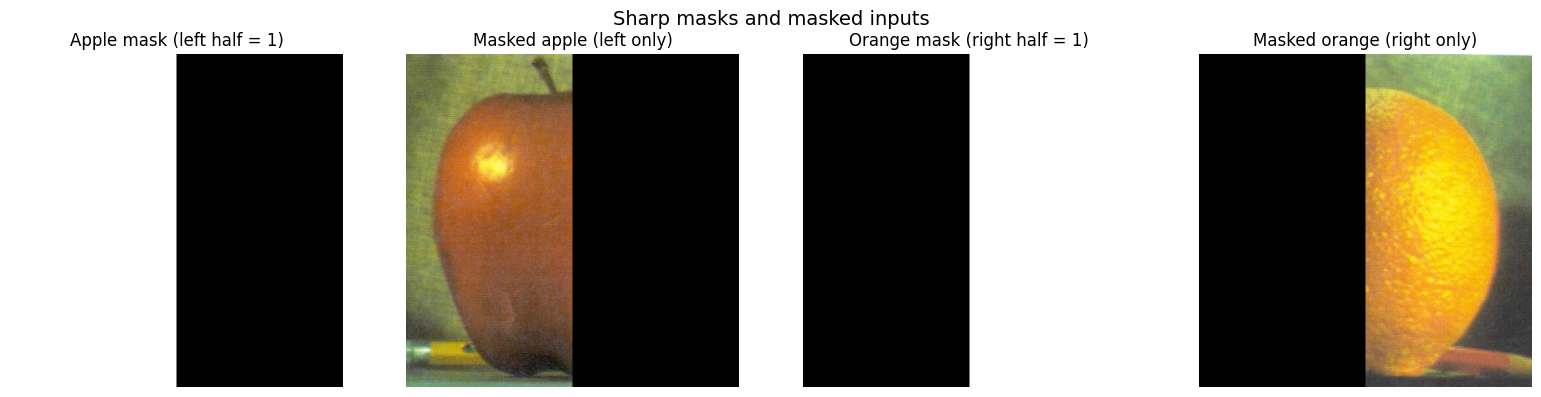

In [24]:
h_apple, w_apple = apple.shape[:2]
mid_x = w_apple // 2

mask_apple_2d = np.zeros(apple.shape[:2], dtype=np.float32)
mask_apple_2d[:, :mid_x] = 1.0
mask_orange_2d = 1.0 - mask_apple_2d

display_masks(mask_apple_2d, mask_orange_2d, apple, orange_aligned)

## 9. The hard cut (the baseline to beat)

A simple pasted cut: keep the left of the apple and the right of the orange
and stick them together. This is the failure case we want to remove.

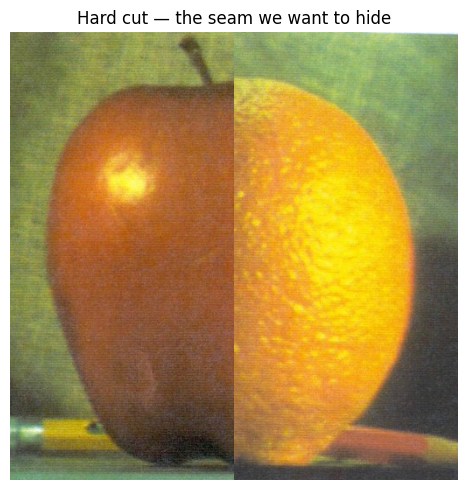

In [25]:
hard_cut = (apple * mask_apple_2d[..., None]
            + orange_aligned * mask_orange_2d[..., None])

plt.figure(figsize=(5, 5))
plt.imshow(np.clip(hard_cut, 0, 1))
plt.title('Hard cut — the seam we want to hide')
plt.axis('off')
plt.tight_layout()
plt.show()

## 10. Pyramid depth sweep

The depth controls how wide the mask's transition becomes at the coarsest
level. On a 512×512 image:

- **4 levels** → coarsest mask ≈ 32×32. Coarse structure still jumps over
  a narrow band → a faint seam remains.
- **5 levels** → coarsest mask ≈ 16×16. Better, but sometimes a soft band
  is still visible.
- **6 levels** → coarsest mask ≈ 8×8. The coarse colour step is smeared
  over ~1/8 of the width → looks natural. **This is our pick.**
- **7 levels** → coarsest mask ≈ 4×4. The transition is very wide, so the
  apple side starts to look orange and the orange side starts to look
  apple — the "washes out a small object" failure the spec warns about.

In the report, show all four so the trade-off is clear.

[Oraple] Blending with 4 pyramid levels...
[Oraple] Blending with 5 pyramid levels...
[Oraple] Blending with 6 pyramid levels...
[Oraple] Blending with 7 pyramid levels...


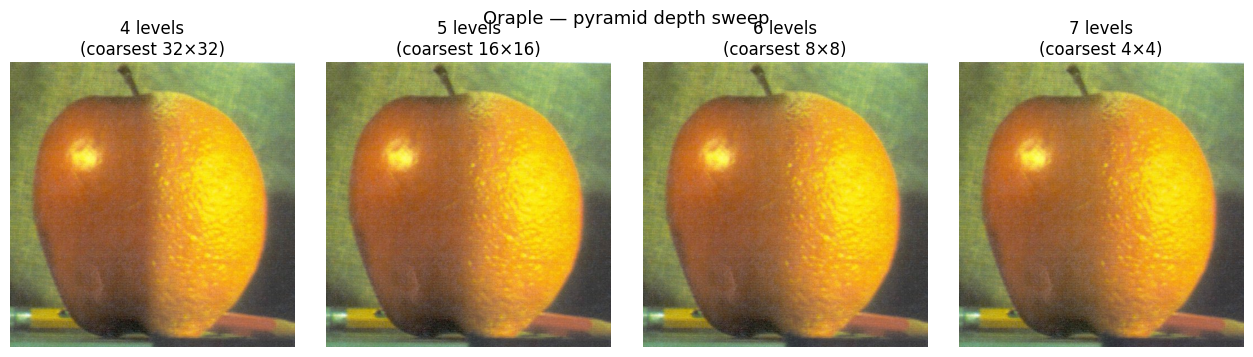

In [26]:
compare_levels('Oraple', apple, orange_aligned, mask_apple_2d, [4, 5, 6, 7])

## 11. Final blend

We pick **7 levels** and show the deliverable figure:

1. the apple (left) and the orange (right),
2. the sharp binary mask,
3. the hard cut (with the visible seam),
4. the multiresolution blend (no visible seam).

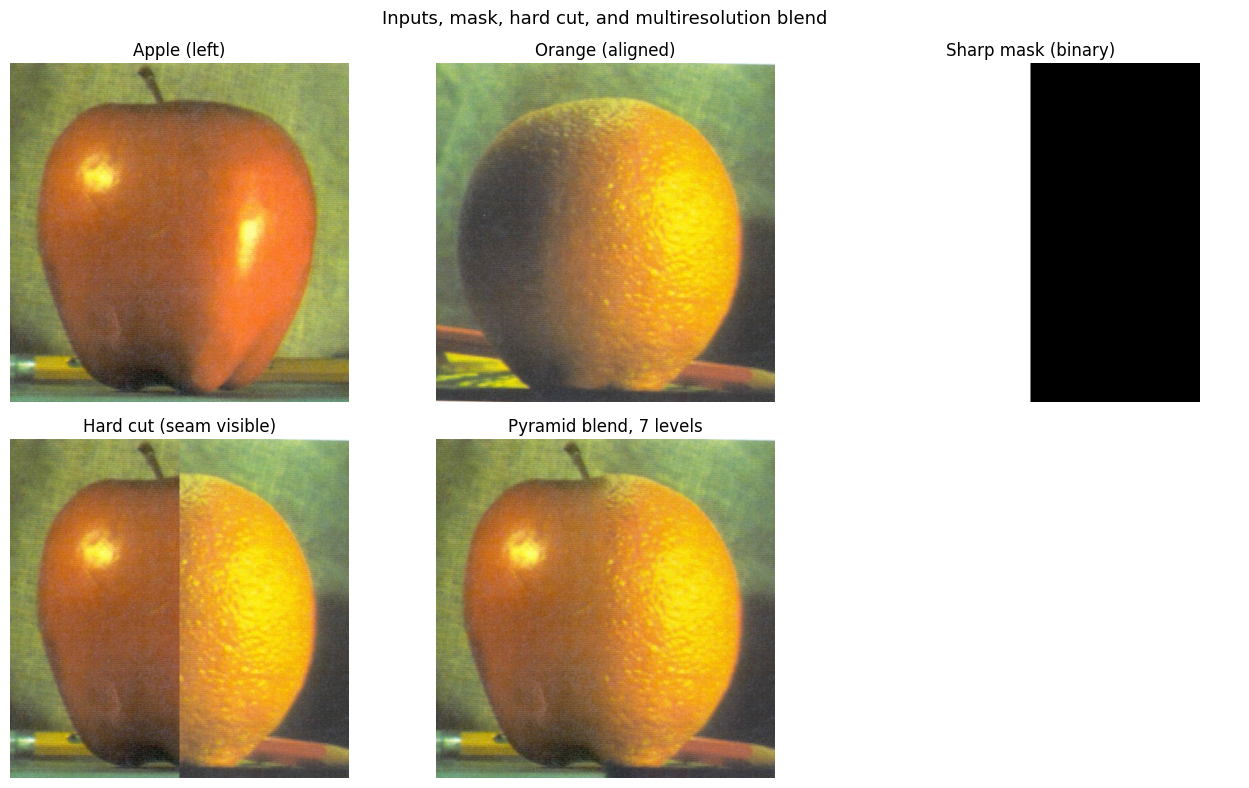

In [31]:
LEVELS = 7

final_blend, lp_left, lp_right, gp_mask, blended_pyramid = blend_multiresolution(
    apple, orange_aligned, mask_apple_2d, levels=LEVELS)

display_report(apple, orange_aligned, mask_apple_2d, hard_cut, final_blend, LEVELS)

## 12. Level-by-level contributions

This is the part that explains **why** the seam is gone. For each level:

- **`M·L1`** — the fine detail of the apple that this level contributes
  (visible only where the mask is white).
- **`(1−M)·L2`** — the fine detail of the orange that this level
  contributes (visible only where the mask is black).
- **`sum`** — what this level contributes to the final image.

Two things to notice:

1. **Fine levels** (top rows). The transition is only a couple of pixels
   wide. That is what the eye expects for texture.
2. **Coarse levels** (bottom rows). The mask has been downsampled and
   re-blurred, so it changes hands over tens of pixels. The big
   brightness / colour difference between the two fruits gets spread over
   a wide region — it looks like a smooth gradient, not a line.

This is the whole point of band-by-band blending: **each band is blended
over a width that matches its own scale.**

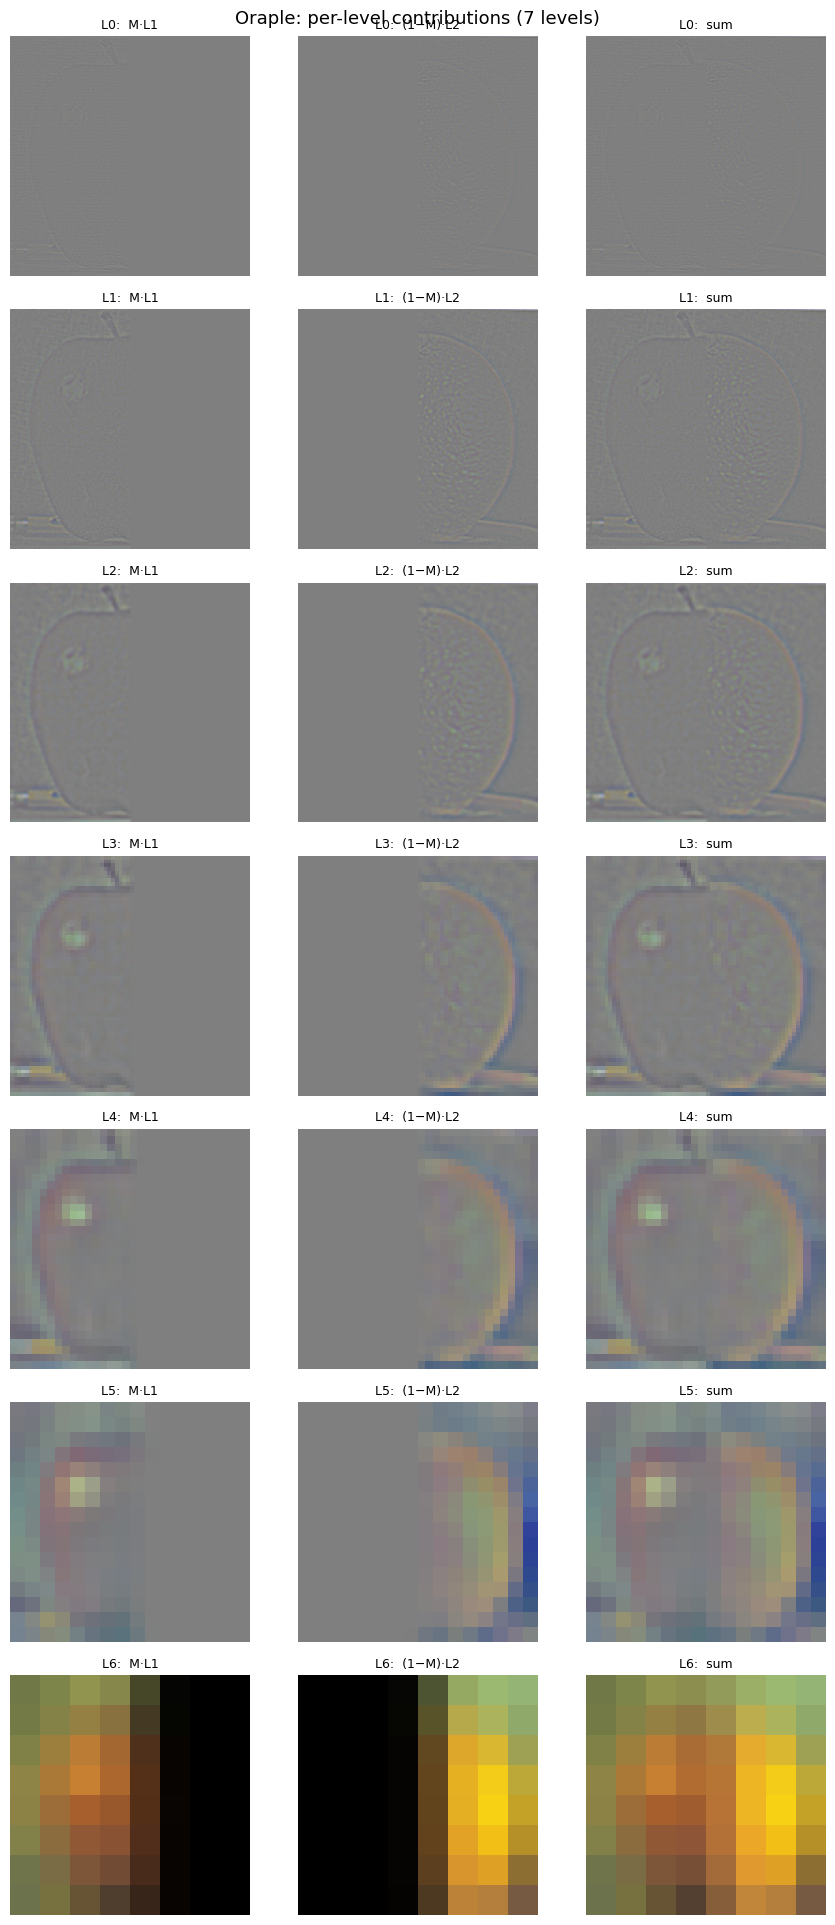

In [28]:
display_bands(lp_left, lp_right, gp_mask, blended_pyramid, 'Oraple')

## 13. Why band-by-band hides the seam

A hard cut is a **step edge**. A step contains energy at every frequency,
so you see a crisp line no matter how you blur a single scale.

The pyramid blend splits each image into bands and blends each band over
its own width:

- **Fine bands** are blended over a couple of pixels. The eye is not
  sensitive to narrow changes at those scales, so no line is visible.
- **Coarse bands** (including the overall colour / brightness) are blended
  over tens or hundreds of pixels. A wide transition carries almost no
  low-frequency energy, so it looks like a gentle gradient.
- **Every band is matched to its own wavelength.** That is precisely what
  the mask's Gaussian pyramid gives us, level by level.

The result: no seam, no harsh colour bleed, and the two fruits still look
like themselves.

### Quick checks

In [29]:
assert final_blend.shape == apple.shape
assert np.isfinite(final_blend).all()
print(f'Multiresolution blend finished with {LEVELS} levels.')
print(f'Coarsest mask level: {gp_mask[-1].shape}  '
      f'(≈ {final_blend.shape[1] // 2**LEVELS}×{final_blend.shape[0] // 2**LEVELS})')

Multiresolution blend finished with 6 levels.
Coarsest mask level: (8, 8)  (≈ 8×8)
